# 4. STEP 3 – 탐색적 데이터 분석(EDA)
## 머신러닝 기반 강판 결함 7개 유형 자동 분류 팀프로젝트 · 실측 결과 보고서

**분석 데이터:** Steel Plates Faults (`steel_plates_faults.csv` / `Faults.NNA`)  
**보고서 근거:** 첨부 자료 `EDA_실측_종합보고서(1).md`, 기존 EDA 코드 및 원본 CSV  
**작성 범위:** 클래스 분포 · 27개 특성 통계 · 면적 · 밝기 · 위치·형상 · 강판 두께·강종 · 상관관계 · 이상값 후보 · 전처리 연계

> **결과의 범위:** 전체 데이터 **1,941건**의 규모·품질·클래스 분포를 기술적으로 확인한다. 변수 분포·상관관계·이상값 탐색은 **Train 1,358건**에서만 수행한다. 검증용 Valid 291건과 최종 평가용 Test 292건의 설명변수 분포를 보고 모델 선택에 활용하지 않는다. 모델 정확도는 이 EDA만으로 입증되지 않는다.

**이 노트북 사용법:** 각 장은 `분석 목적 → 실행 코드·수치·그래프 → 보고서에 쓸 해석`으로 구성되어 있다. `셀 모두 실행(Run All)`하면 표와 그림이 갱신되고, 이미지·CSV는 `results/eda_notebook/`에 저장된다. 아래에 포함된 실행 출력은 첨부 원본 CSV로 검증된 결과다.

### 4-1. 분석 목표와 연구 질문

EDA는 학습 이전에 데이터의 중심·산포·유형별 차이·중복된 정보를 탐색하고, 후속 전처리·모델 비교에 필요한 가설을 수립하는 과정이다.

| 연구 질문 | 검토 방법 | 후속 단계와의 관계 |
|---|---|---|
| 7개 결함 유형의 표본 수가 균형적인가? | 클래스별 빈도·비율·최대/최소 비율 | 층화분할, Macro F1·클래스별 Recall 평가 |
| 면적·밝기·형상·위치가 결함 유형마다 다른가? | 중앙값·IQR·박스플롯·산점도 | 후보 특성의 예측 기여도 검증 |
| 변수들 사이에 중복된 정보가 있는가? | 피어슨 상관계수, 상위 변수 쌍 | 다중공선성 및 중요도 해석 |
| 극단값은 오류인가, 결함 유형의 특징인가? | IQR 후보·클래스별 분포 | 근거 없는 일괄 제거 방지 |

**분석 해석 원칙:** EDA에서 관찰되는 관계는 기술적·통계적 연관성이다. 원인이나 실제 모델 성능을 확정하지 않는다.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 170)
plt.rcParams["axes.unicode_minus"] = False

FAULT_COLS = ["Pastry", "Z_Scratch", "K_Scatch", "Stains", "Dirtiness", "Bumps", "Other_Faults"]
RANDOM_STATE = 42
BASE_DIR = Path.cwd()
OUT_DIR = BASE_DIR / "results" / "eda_notebook"
OUT_DIR.mkdir(parents=True, exist_ok=True)

def get_data():
    paths = [BASE_DIR / "steel_plates_faults.csv", BASE_DIR / "steel_plates_faults(1).csv",
             BASE_DIR / "data" / "steel_plates_faults.csv", BASE_DIR / "data" / "steel_plates_faults(1).csv"]
    for p in paths:
        if p.exists():
            return pd.read_csv(p), str(p)
    for raw_name, cols_name in [("Faults.NNA", "Faults27x7_var"), ("Faults(1).NNA", "Faults27x7_var(1)")]:
        for folder in [BASE_DIR, BASE_DIR / "data"]:
            rp, cp = folder / raw_name, folder / cols_name
            if rp.exists() and cp.exists():
                names = [r.strip() for r in cp.read_text(encoding="utf-8-sig").splitlines() if r.strip()]
                return pd.read_csv(rp, sep=r"\s+", header=None, names=names), str(rp)
    raise FileNotFoundError("프로젝트 폴더 또는 data 폴더에 steel_plates_faults.csv 파일을 넣어주세요.")

def save_table(table, filename, index=True):
    table.to_csv(OUT_DIR / filename, index=index, encoding="utf-8-sig")

def save_figure(filename):
    plt.tight_layout()
    plt.savefig(OUT_DIR / filename, dpi=160, bbox_inches="tight")
    plt.show()

df, DATA_SOURCE = get_data()
assert set(FAULT_COLS).issubset(df.columns), "7개 정답 열을 찾을 수 없습니다."
assert df[FAULT_COLS].isin([0, 1]).all().all(), "정답에 0/1 외 값이 있습니다."
assert (df[FAULT_COLS].sum(axis=1) == 1).all(), "각 행에서 정확히 한 정답이 1이어야 합니다."
FEATURE_COLS = [c for c in df.columns if c not in FAULT_COLS + ["Fault", "target"]]
assert len(FEATURE_COLS) == 27, f"입력 특성 개수 오류: {len(FEATURE_COLS)}"
df = df.drop(columns=[c for c in ["Fault", "target"] if c in df.columns]).copy()
df["Fault"] = df[FAULT_COLS].idxmax(axis=1)

# STEP 4 전처리 노트북과 동일: 층화 Train 70% / Valid 15% / Test 15%
dev_df, test_df = train_test_split(df, test_size=0.15, stratify=df["Fault"], random_state=RANDOM_STATE)
train_df, valid_df = train_test_split(dev_df, test_size=0.15/0.85,
                                    stratify=dev_df["Fault"], random_state=RANDOM_STATE)
eda = train_df.copy()  # 상세 통계는 학습용 원본 측정값에 대해서만 수행
assert len(train_df) == 1358 and len(valid_df) == 291 and len(test_df) == 292

quality_table = pd.DataFrame({
    "항목": ["원본 관측치", "입력 특성 수", "결함 유형 수", "원본 결측값(입력)",
           "원본 완전 중복 행", "정답 원-핫 오류", "Train", "Valid", "Test"],
    "실측값": [len(df), len(FEATURE_COLS), len(FAULT_COLS),
            int(df[FEATURE_COLS].isna().sum().sum()), int(df.duplicated().sum()),
            int((df[FAULT_COLS].sum(axis=1) != 1).sum()), len(train_df), len(valid_df), len(test_df)]
})
save_table(quality_table, "01_data_quality.csv", index=False)
print("데이터 위치:", DATA_SOURCE)
display(quality_table)

데이터 위치: /mnt/data/steel_plates_faults(1).csv


,항목,실측값
0,원본 관측치,1941
1,입력 특성 수,27
2,결함 유형 수,7
3,원본 결측값(입력),0
4,원본 완전 중복 행,0
5,정답 원-핫 오류,0
6,Train,1358
7,Valid,291
8,Test,292


**[분석 결과 및 해석]** 원본은 **1,941행 × 34열**이며 입력 특성 27개와 정답 표시 열 7개로 구성되어 있다. 원본 입력 결측값 0칸, 완전 중복 행 0건, 유효하지 않은 원-핫 정답 0건으로 확인되었다. 이는 이번 자료에서 해당 항목에 별도 보정이 필요하지 않음을 의미하지만, 데이터에 모든 측정 오류가 없다는 뜻은 아니다. 층화분할 후 Train **1,358건**, Valid **291건**, Test **292건**으로 구분하였다.

### 4-2. 결함 유형별 분포 및 클래스 불균형

**분석 목적:** 어느 결함 유형이 다수/소수인지 확인하고 향후 평가 지표를 정한다. 클래스 분포는 전체 원본 1,941건을 기준으로 제시한다.

,관측치(건),구성비(%)
Fault,,
Pastry,158.0,8.14
Z_Scratch,190.0,9.79
K_Scatch,391.0,20.14
Stains,72.0,3.71
Dirtiness,55.0,2.83
Bumps,402.0,20.71
Other_Faults,673.0,34.67
합계,1941.0,100.00


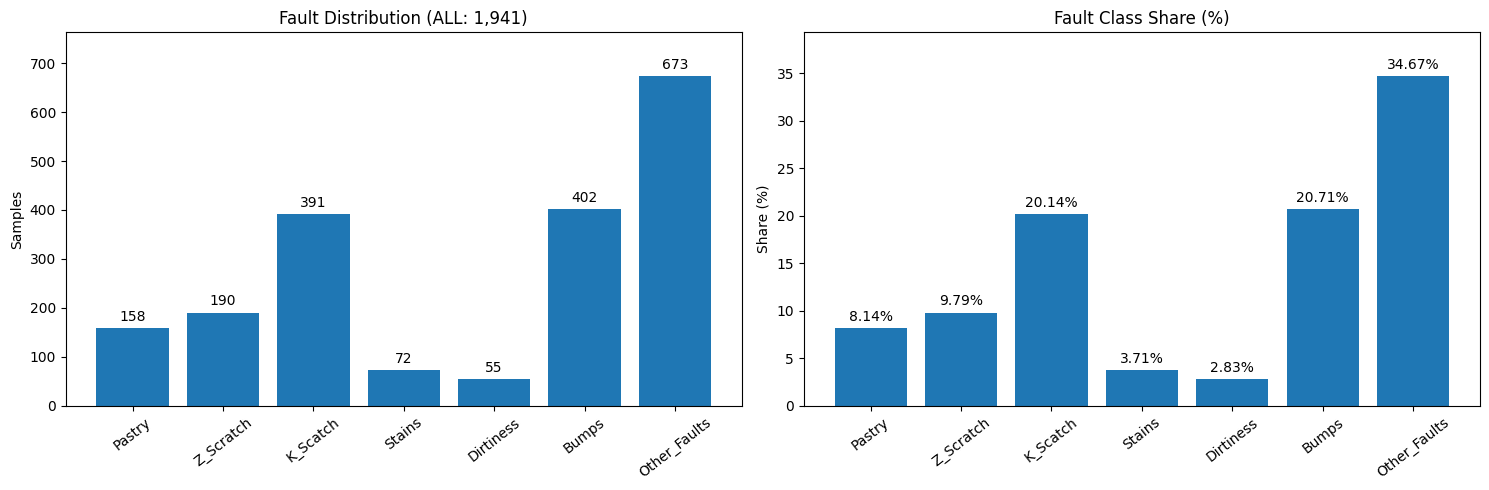

,전체,Train,Valid,Test
Fault,,,,
Pastry,158,110,24,24
Z_Scratch,190,133,28,29
K_Scatch,391,273,59,59
Stains,72,50,11,11
Dirtiness,55,39,8,8
Bumps,402,282,60,60
Other_Faults,673,471,101,101


최대/최소 클래스 비율: 12.24배


In [2]:
counts = df["Fault"].value_counts().reindex(FAULT_COLS, fill_value=0)
class_table = pd.DataFrame({"관측치(건)": counts.astype(int), "구성비(%)": (counts/len(df)*100).round(2)})
class_table.loc["합계"] = [int(counts.sum()), 100.00]
display(class_table)
save_table(class_table, "02_class_distribution.csv")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
bar1 = axes[0].bar(counts.index, counts.values)
axes[0].bar_label(bar1, padding=3)
axes[0].set(title="Fault Distribution (ALL: 1,941)", ylabel="Samples")
bar2 = axes[1].bar(counts.index, counts.values/len(df)*100)
axes[1].bar_label(bar2, labels=[f"{x:.2f}%" for x in counts/len(df)*100], padding=3)
axes[1].set(title="Fault Class Share (%)", ylabel="Share (%)")
for ax in axes:
    ax.tick_params(axis="x", rotation=38)
    ax.set_ylim(0, ax.get_ylim()[1]*1.08)
save_figure("02_fault_distribution.png")

split_table = pd.DataFrame({
    "전체": df["Fault"].value_counts(), "Train": train_df["Fault"].value_counts(),
    "Valid": valid_df["Fault"].value_counts(), "Test": test_df["Fault"].value_counts()
}).reindex(FAULT_COLS).astype(int)
display(split_table)
save_table(split_table, "03_split_class_counts.csv")
print(f"최대/최소 클래스 비율: {counts.max()/counts.min():.2f}배")

**[실측 결과]** 가장 많은 결함 유형은 `Other_Faults` **673건(34.67%)**, 가장 적은 결함 유형은 `Dirtiness` **55건(2.83%)**으로 **12.24배** 차이를 보인다. `Bumps` 402건(20.71%), `K_Scatch` 391건(20.14%)은 상대적으로 많고, `Stains` 72건(3.71%)도 소수 유형에 해당한다. 나머지는 Pastry 158건(8.14%), Z_Scratch 190건(9.79%)이다.

**[그래프 해석]** 막대그래프의 높이 차이는 표본 수 불균형이 실재함을 나타낸다. 이 분포에서 단순 다수 유형 예측만으로도 34.67%의 정확도가 가능하므로, 정확도만으로 분류 품질을 평가해서는 안 된다. 이후 모델 비교에서는 **Macro F1, Macro Recall, 클래스별 Precision/Recall/F1**을 함께 확인하고, Train에만 가중치·샘플링을 적용하여 성능 변화를 검증한다. 이 수치는 불균형의 규모이지 학습된 모델의 실측 성능은 아니다.

### 4-3. 27개 입력 변수의 기초통계 및 분포

**분석 목적:** 변수의 값 범위, 중심값, 산포와 왜도(한쪽 치우침)를 파악하여 스케일링·변환 후보를 찾는다. 이 절부터는 **Train 1,358건**의 원본 측정값만 분석한다.

27개 입력 변수 전체 통계 (아래 표는 핵심 열만 표시, 전체는 CSV로 저장)


,mean,50%,std,min,max,skewness,IQR
X_Minimum,561.19,397.50,519.88,0.00,1688.00,0.56,984.75
X_Maximum,609.37,442.50,496.98,4.00,1712.00,0.58,866.75
Y_Minimum,1667921.99,1194579.50,1820361.96,6712.00,12987661.00,2.82,1696926.25
Y_Maximum,1667967.03,1194614.00,1820360.24,6724.00,12987692.00,2.82,1696775.50
Pixels_Areas,1866.15,178.00,3960.57,2.00,37334.00,3.16,788.75
X_Perimeter,107.97,27.00,190.48,2.00,1275.00,2.87,76.00
Y_Perimeter,74.79,25.00,118.29,1.00,903.00,2.83,71.75
Sum_of_Luminosity,205808.32,19603.50,452316.74,250.00,3918209.00,3.29,77793.75
Minimum_of_Luminosity,84.44,90.00,32.23,0.00,203.00,-0.09,43.00
Maximum_of_Luminosity,129.95,127.00,18.49,39.00,252.00,1.17,16.00


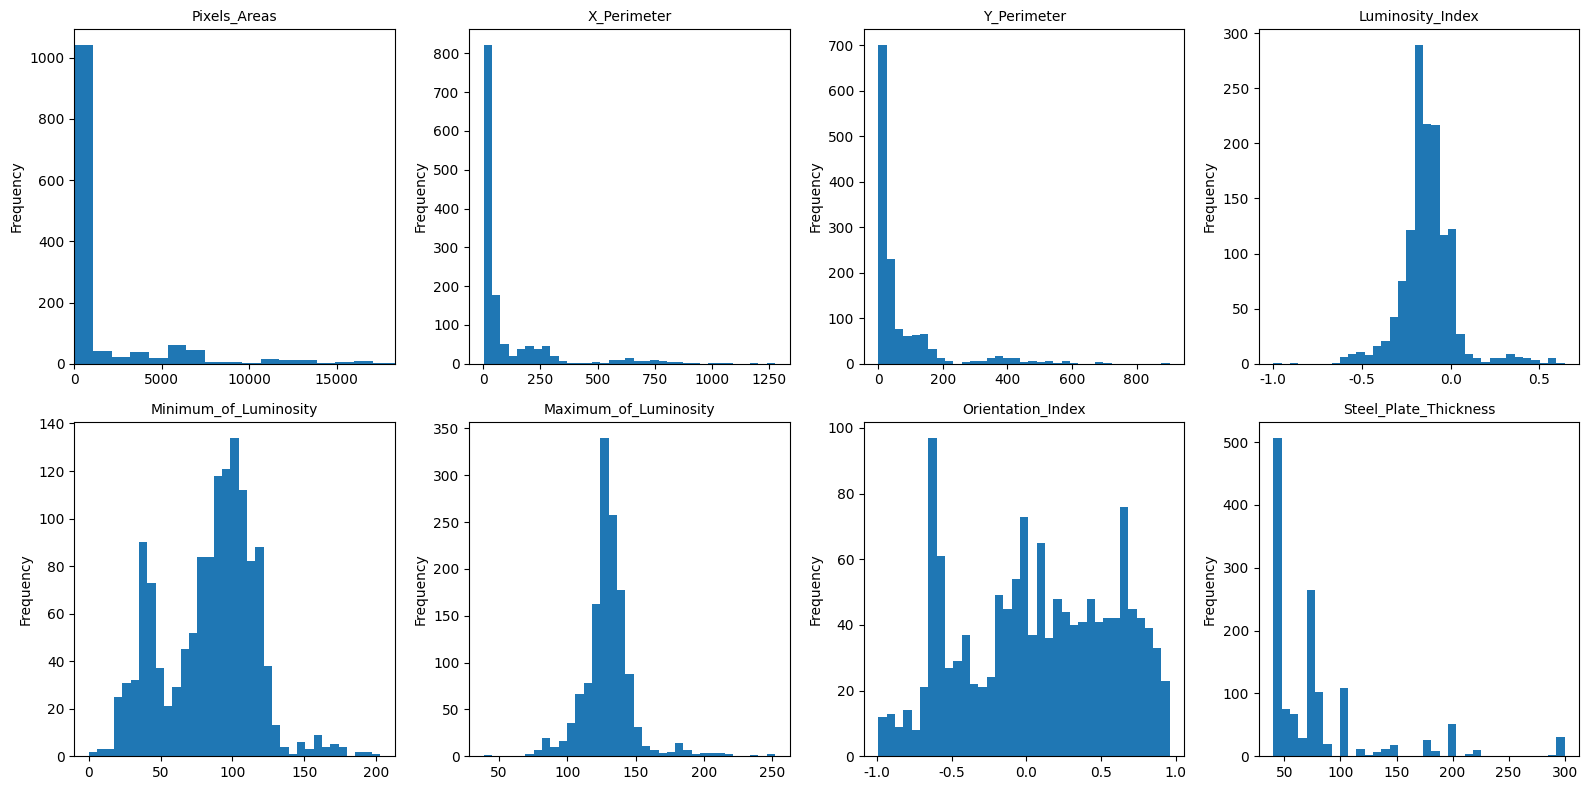

In [3]:
feat_stats = eda[FEATURE_COLS].describe().T
feat_stats["median"] = eda[FEATURE_COLS].median()
feat_stats["IQR"] = feat_stats["75%"] - feat_stats["25%"]
feat_stats["skewness"] = eda[FEATURE_COLS].skew()
feat_stats["missing_count"] = eda[FEATURE_COLS].isna().sum()
feat_stats["unique_values"] = eda[FEATURE_COLS].nunique()
save_table(feat_stats.round(5), "04_all_27_feature_statistics.csv")
print("27개 입력 변수 전체 통계 (아래 표는 핵심 열만 표시, 전체는 CSV로 저장)")
display(feat_stats[["mean", "50%", "std", "min", "max", "skewness", "IQR"]].round(2))

plot_features = ["Pixels_Areas", "X_Perimeter", "Y_Perimeter", "Luminosity_Index",
                 "Minimum_of_Luminosity", "Maximum_of_Luminosity", "Orientation_Index", "Steel_Plate_Thickness"]
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, feature in zip(axes.flat, plot_features):
    values = eda[feature].dropna()
    ax.hist(values, bins=35)
    ax.set_title(feature, fontsize=10)
    ax.set_ylabel("Frequency")
    if values.max() > values.quantile(0.99)*2 and values.min() >= 0:
        ax.set_xlim(0, values.quantile(0.99))
save_figure("04_selected_feature_histograms.png")

**[실측 결과]** 학습용 데이터에서 `Pixels_Areas`의 **평균 1,866.15**, **중앙값 178.0**, **표준편차 3,960.57**, **최댓값 37,334**로 확인되었다. 평균이 중앙값보다 훨씬 크고 왜도는 약 **3.16**으로 오른쪽 꼬리가 긴 분포를 보인다. 반면 `Orientation_Index`는 중앙값 약 **0.09**, `Luminosity_Index`는 중앙값 약 **-0.14**로, 변수별 측정 범위가 매우 다르다.

**[그래프 해석]** 크기 관련 변수의 일부 큰 값 때문에 대부분의 표본이 낮은 값 구간에 모여 보일 수 있다. 이는 로그 축·로그 변환을 **검토할 근거**이나, 실제 적용 및 기준 학습은 Train 내부에서 해야 한다. 로지스틱 회귀처럼 크기에 민감한 모델에서는 스케일러를 Train에 `fit`하고 Valid/Test에 `transform`만 적용한다.

### 4-4. 결함 면적과 경계 특성의 유형별 차이

**분석 목적:** 결함 유형별로 픽셀 면적(`Pixels_Areas`)과 X·Y 경계값의 크기 및 분포가 달라지는지 확인한다.

,Pixels_Areas,X_Perimeter,Y_Perimeter,LogOfAreas,SigmoidOfAreas
Fault,,,,,
Pastry,212.5,20.0,31.0,2.33,0.55
Z_Scratch,170.0,30.0,25.0,2.23,0.51
K_Scatch,6282.0,269.0,138.0,3.80,1.00
Stains,17.0,7.0,5.0,1.23,0.14
Dirtiness,144.0,28.0,35.0,2.16,0.41
Bumps,122.0,17.0,16.0,2.09,0.32
Other_Faults,147.0,25.0,22.0,2.17,0.42


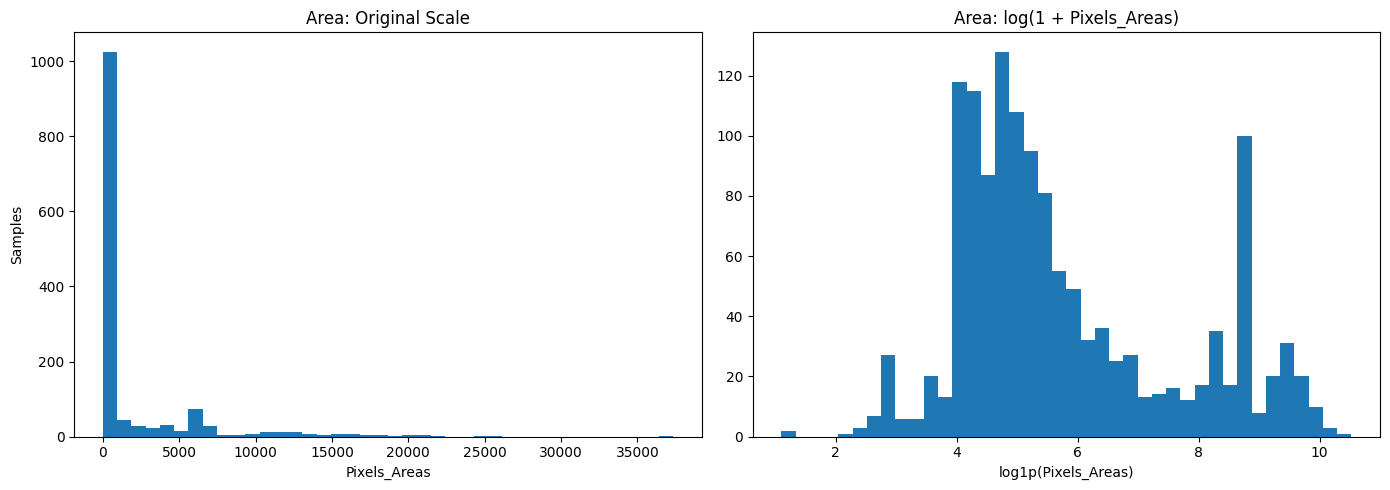

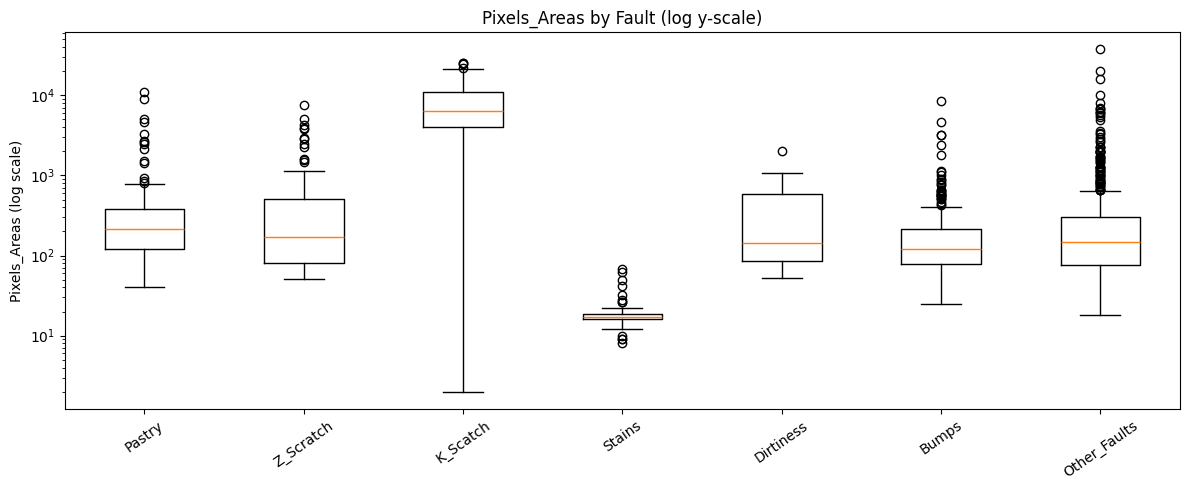

In [4]:
size_features = ["Pixels_Areas", "X_Perimeter", "Y_Perimeter", "LogOfAreas", "SigmoidOfAreas"]
size_medians = eda.groupby("Fault")[size_features].median().reindex(FAULT_COLS)
save_table(size_medians.round(3), "05_fault_size_medians.csv")
display(size_medians.round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist(eda["Pixels_Areas"], bins=40)
axes[0].set(title="Area: Original Scale", xlabel="Pixels_Areas", ylabel="Samples")
axes[1].hist(np.log1p(eda["Pixels_Areas"]), bins=40)
axes[1].set(title="Area: log(1 + Pixels_Areas)", xlabel="log1p(Pixels_Areas)")
save_figure("05_area_original_vs_log.png")

fig, ax = plt.subplots(figsize=(12, 5))
ax.boxplot([eda.loc[eda.Fault==k, "Pixels_Areas"] for k in FAULT_COLS], tick_labels=FAULT_COLS, showfliers=True)
ax.set_yscale("log")
ax.set(title="Pixels_Areas by Fault (log y-scale)", ylabel="Pixels_Areas (log scale)")
ax.tick_params(axis="x", rotation=35)
save_figure("06_area_boxplot_by_fault.png")

**[실측 결과]** `Pixels_Areas` 중앙값은 `Stains` **17.0픽셀**, `Bumps` **122.0**, `Dirtiness` **144.0**, `Other_Faults` **147.0**, `Z_Scratch` **170.0**, `Pastry` **212.5**, `K_Scatch` **6,282.0**이다. 전체 Train의 면적 중앙값은 **178.0픽셀**이다. 특히 `K_Scatch`의 중앙값은 `Stains`의 약 **369.5배**이다(6,282 ÷ 17).

**[그래프 해석]** 로그 축 박스플롯에서 `K_Scatch`는 다른 유형보다 큰 면적 구간에 분포하는 경향이 나타난다. 따라서 결함 크기는 유형 구분의 유력한 **후보 정보**이다. 반면 여러 유형의 면적 범위가 겹치므로 면적 단일 변수만으로 충분한 분류가 가능한지는 검증되지 않았다. `Pixels_Areas`와 변환 변수(`LogOfAreas`, `SigmoidOfAreas`)의 정보 중복도 후속 상관관계 분석에서 확인한다.

### 4-5. 밝기·명암 특성 분석

**분석 목적:** 결함 유형별 최소·최대 밝기와 밝기 관련 지표가 서로 다른지 확인하고, 밝기 합계(`Sum_of_Luminosity`)를 면적과 구분해서 해석한다.

,Sum_of_Luminosity,Minimum_of_Luminosity,Maximum_of_Luminosity,Luminosity_Index
Fault,,,,
Pastry,22171.0,80.0,126.0,-0.18
Z_Scratch,18517.0,93.0,124.0,-0.17
K_Scatch,652005.0,40.0,132.0,-0.16
Stains,2162.0,115.5,141.0,-0.00
Dirtiness,17271.0,107.0,133.0,-0.09
Bumps,13323.5,91.0,127.0,-0.14
Other_Faults,16891.0,97.0,127.0,-0.12


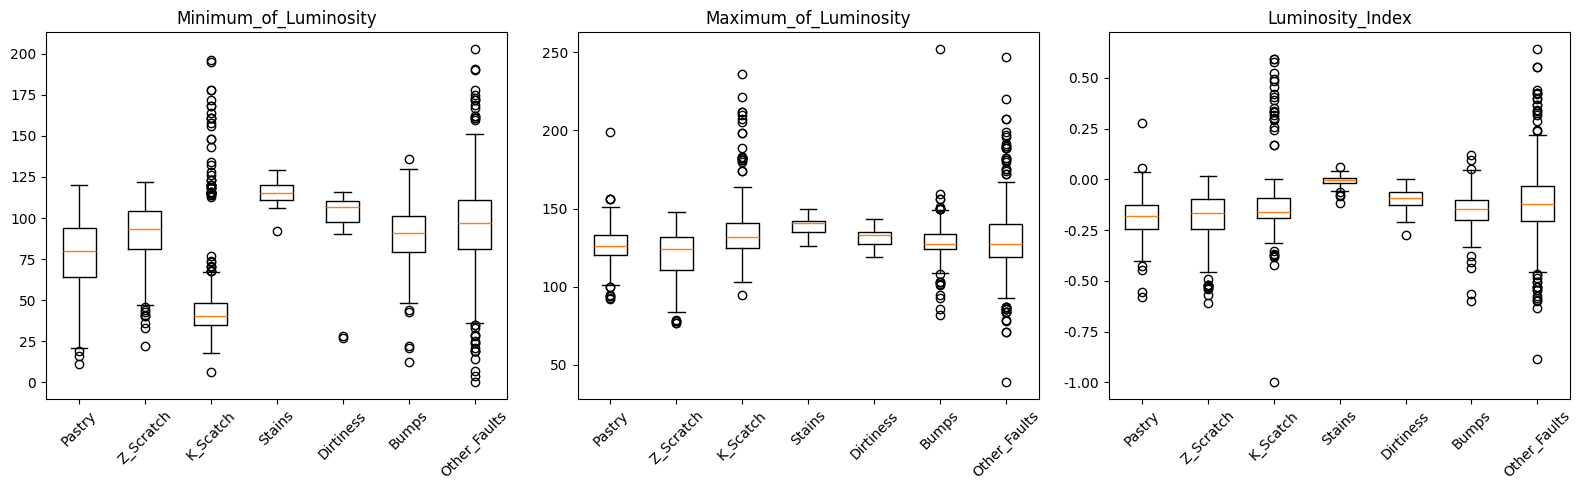

In [5]:
brightness_features = ["Sum_of_Luminosity", "Minimum_of_Luminosity", "Maximum_of_Luminosity", "Luminosity_Index"]
brightness_medians = eda.groupby("Fault")[brightness_features].median().reindex(FAULT_COLS)
save_table(brightness_medians.round(3), "06_fault_brightness_medians.csv")
display(brightness_medians.round(2))

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, feature in zip(axes, ["Minimum_of_Luminosity", "Maximum_of_Luminosity", "Luminosity_Index"]):
    ax.boxplot([eda.loc[eda.Fault==k, feature] for k in FAULT_COLS], tick_labels=FAULT_COLS)
    ax.set_title(feature)
    ax.tick_params(axis="x", rotation=45)
save_figure("07_brightness_by_fault.png")

**[실측 결과]** Train의 `Minimum_of_Luminosity` 중앙값은 `K_Scatch` **40.0**, `Stains` **115.5**, `Dirtiness` **107.0**이다. `Luminosity_Index` 중앙값도 유형에 따라 차이가 나타난다(예: `Pastry` 약 **-0.18**, `Dirtiness` 약 **-0.09**, `Stains` 약 **0.00**).

**[그래프 해석]** 최소 밝기 분포에 유형별 차이가 있어 명암 정보도 분류에 활용될 가능성이 있다. 단, `Sum_of_Luminosity`는 면적이 큰 결함에서 값이 커지기 쉬우므로 총 밝기를 단순한 '결함의 밝기'와 동일시하지 않는다. 유사한 밝기 분포가 있다고 해서 특정 유형들 사이에 오분류가 **이미 발생했다**고 판단할 수 없으며, 이는 이후 혼동행렬에서 확인한다.

### 4-6. 결함 좌표·형상·방향성 분석

**분석 목적:** X·Y 좌표 범위, 방향성(`Orientation_Index`), 형상 관련 지표(`Square_Index` 등)의 결함별 차이를 살펴본다. 좌표를 시간 또는 공정 원인으로 해석하지 않는다.

,X_Range,Y_Range,Orientation_Index,Square_Index,Edges_Index
Fault,,,,,
Pastry,10.0,31.0,0.67,0.33,0.15
Z_Scratch,15.0,21.0,0.36,0.57,0.14
K_Scatch,155.0,67.0,-0.57,0.43,0.06
Stains,6.0,4.5,-0.29,0.69,0.47
Dirtiness,10.0,35.0,0.82,0.18,0.90
Bumps,13.0,14.5,0.10,0.75,0.45
Other_Faults,14.0,18.0,0.18,0.55,0.32


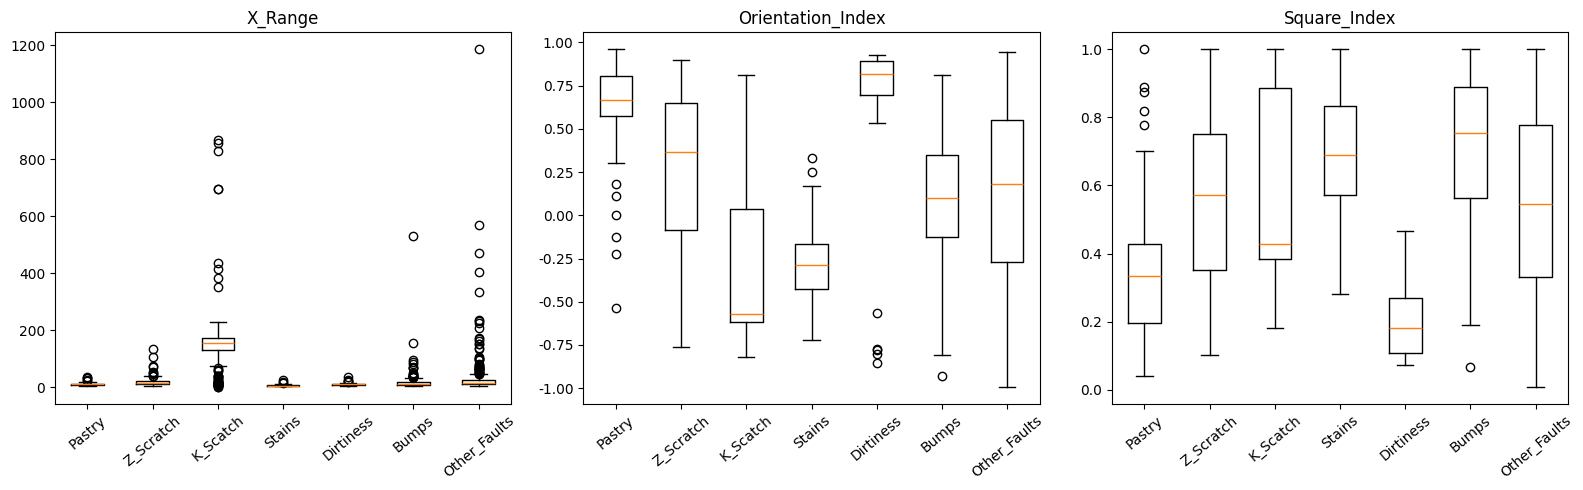

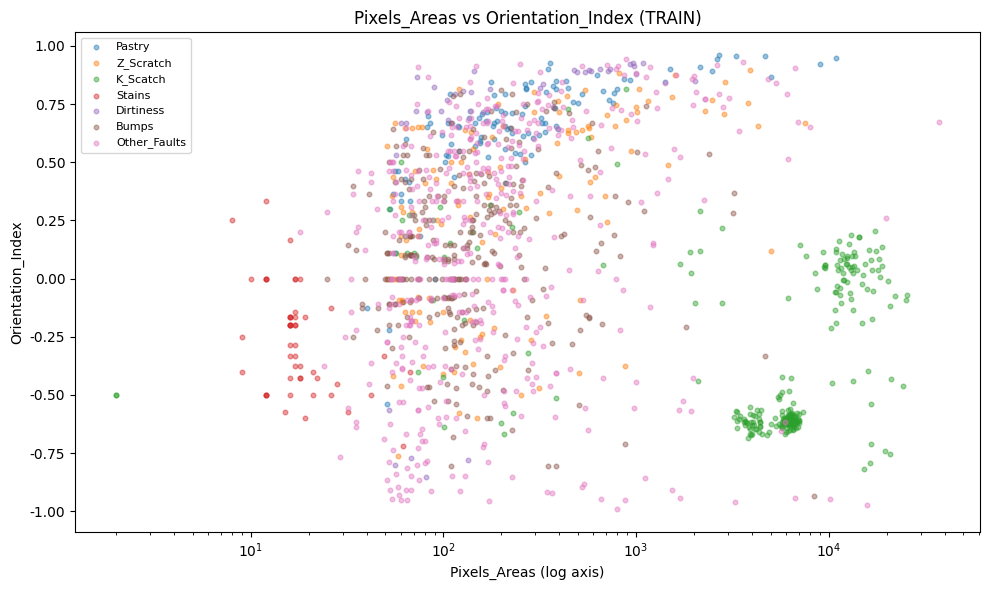

In [6]:
# 파생 변수는 EDA에서만 사용하며, 원본 파일이나 학습용 입력 파일에 덮어쓰지 않음
eda = eda.assign(X_Range=eda["X_Maximum"] - eda["X_Minimum"],
                 Y_Range=eda["Y_Maximum"] - eda["Y_Minimum"])
shape_features = ["X_Range", "Y_Range", "Orientation_Index", "Square_Index", "Edges_Index"]
shape_medians = eda.groupby("Fault")[shape_features].median().reindex(FAULT_COLS)
save_table(shape_medians.round(3), "07_fault_location_shape_medians.csv")
display(shape_medians.round(2))

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, feature in zip(axes, ["X_Range", "Orientation_Index", "Square_Index"]):
    ax.boxplot([eda.loc[eda.Fault==k, feature] for k in FAULT_COLS], tick_labels=FAULT_COLS)
    ax.set_title(feature)
    ax.tick_params(axis="x", rotation=40)
save_figure("08_shape_location_boxplots.png")

fig, ax = plt.subplots(figsize=(10, 6))
for fault in FAULT_COLS:
    subset = eda.loc[eda.Fault==fault]
    ax.scatter(subset["Pixels_Areas"], subset["Orientation_Index"], alpha=.45, s=11, label=fault)
ax.set(xscale="log", xlabel="Pixels_Areas (log axis)", ylabel="Orientation_Index",
       title="Pixels_Areas vs Orientation_Index (TRAIN)")
ax.legend(loc="best", fontsize=8)
save_figure("09_area_orientation_scatter.png")

**[실측 결과]** `Orientation_Index` 중앙값은 `K_Scatch` 약 **-0.57**, `Dirtiness` 약 **0.82**, `Pastry` 약 **0.67**로 서로 차이가 있다. `Edges_Index` 중앙값도 `K_Scatch` 약 **0.06**, `Dirtiness` 약 **0.90**으로 차이를 보인다.

**[그래프 해석]** 면적과 방향성을 함께 놓으면 유형별 데이터가 일부 다른 영역에 분포하지만, 겹치는 관측치도 존재한다. 위치·형상 특성의 조합이 분류에 도움을 주는지는 후속 모델에서 확인해야 한다. 원본 데이터에는 생산 배치·시간 순서를 보장하는 정보가 없으므로 좌표값만으로 발생 시점이나 설비 문제를 단정하지 않는다.

### 4-7. 강판 두께와 강종에 따른 차이

**분석 목적:** 강판 두께(`Steel_Plate_Thickness`) 및 0/1 강종 표시 변수(`TypeOfSteel_A300`, `TypeOfSteel_A400`)가 유형 분포와 함께 어떻게 변하는지 파악한다.

,두께 중앙값
Fault,
Pastry,70.0
Z_Scratch,70.0
K_Scatch,40.0
Stains,50.0
Dirtiness,100.0
Bumps,70.0
Other_Faults,70.0


강종 이진 표시가 모든 행에서 배타적인가?: True


col_0,A300,A400
Fault,,
Pastry,37,73
Z_Scratch,121,12
K_Scatch,0,273
Stains,1,49
Dirtiness,6,33
Bumps,189,93
Other_Faults,195,276


col_0,A300,A400
Fault,,
Pastry,33.64,66.36
Z_Scratch,90.98,9.02
K_Scatch,0.00,100.00
Stains,2.00,98.00
Dirtiness,15.38,84.62
Bumps,67.02,32.98
Other_Faults,41.40,58.60


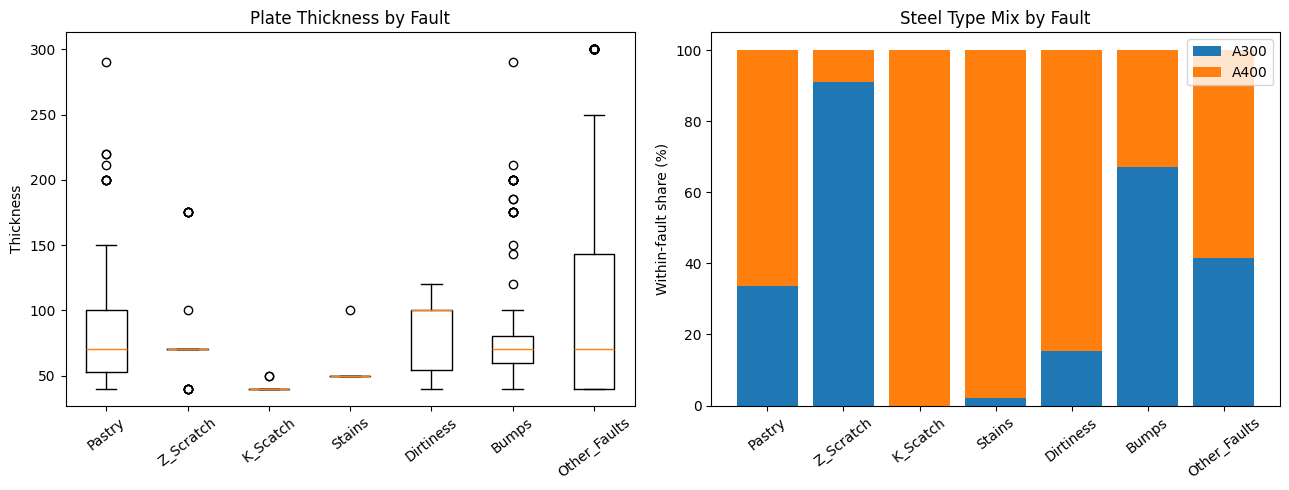

In [7]:
thickness_medians = eda.groupby("Fault")["Steel_Plate_Thickness"].median().reindex(FAULT_COLS)
display(thickness_medians.to_frame("두께 중앙값"))
save_table(thickness_medians.to_frame("Thickness_Median"), "08_fault_thickness_medians.csv")

# A300/A400이 상호 배타적인지 먼저 검증
steel_binary_valid = (eda[["TypeOfSteel_A300", "TypeOfSteel_A400"]].sum(axis=1)==1).all()
print("강종 이진 표시가 모든 행에서 배타적인가?:", steel_binary_valid)
steel_group = np.where(eda["TypeOfSteel_A300"]==1, "A300", "A400")
steel_counts = pd.crosstab(eda["Fault"], steel_group).reindex(FAULT_COLS)
steel_percent = steel_counts.div(steel_counts.sum(axis=1), axis=0)*100
display(steel_counts)
display(steel_percent.round(2))
save_table(steel_counts, "09_steel_type_counts.csv")
save_table(steel_percent.round(2), "10_steel_type_share_by_fault.csv")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].boxplot([eda.loc[eda.Fault==k, "Steel_Plate_Thickness"] for k in FAULT_COLS], tick_labels=FAULT_COLS)
axes[0].set(title="Plate Thickness by Fault", ylabel="Thickness")
axes[0].tick_params(axis="x", rotation=38)
xpos = np.arange(len(FAULT_COLS))
axes[1].bar(xpos, steel_percent["A300"], label="A300")
axes[1].bar(xpos, steel_percent["A400"], bottom=steel_percent["A300"], label="A400")
axes[1].set(xticks=xpos, xticklabels=FAULT_COLS, ylabel="Within-fault share (%)", title="Steel Type Mix by Fault")
axes[1].tick_params(axis="x", rotation=38)
axes[1].legend()
save_figure("10_thickness_steel_type.png")

**[실측 결과]** Train에서 강종 이진 열은 모든 행에서 A300/A400 중 정확히 하나가 1이다. `Steel_Plate_Thickness` 중앙값은 예를 들어 `K_Scatch` **40.0**, `Dirtiness` **100.0**, `Pastry` **70.0**이다. 결함 유형별로 강종 구성비도 서로 다르게 나타난다(정확한 빈도·비율은 위 표).

**[그래프 해석]** 강판의 물리적 조건과 결함 유형 사이에 **연관성이 관찰될 수 있지만**, 두께나 강종이 특정 결함의 원인이라는 결론은 내릴 수 없다. 추후 분류 모델에 이 변수를 유지할지 여부는 검증 성능과 중요도 결과를 함께 고려한다.

### 4-8. 27개 입력 변수 간 피어슨 상관관계

**분석 목적:** 강한 선형 관계가 있는 변수 쌍을 식별하여 중복 정보·다중공선성 가능성을 탐색한다. `|r| ≥ 0.80`은 **탐색·보고 기준**이며 자동 삭제 기준이 아니다.

,변수1,변수2,상관계수_r
231,TypeOfSteel_A300,TypeOfSteel_A400,-1.0000
51,Y_Minimum,Y_Maximum,1.0000
100,Pixels_Areas,Sum_of_Luminosity,0.9964
0,X_Minimum,X_Maximum,0.9870
121,X_Perimeter,Sum_of_Luminosity,0.9578
98,Pixels_Areas,X_Perimeter,0.9558
120,X_Perimeter,Y_Perimeter,0.9507
141,Y_Perimeter,Sum_of_Luminosity,0.9334
99,Pixels_Areas,Y_Perimeter,0.9304
336,LogOfAreas,Log_X_Index,0.8913


|r| >= 0.80인 변수쌍 수: 19


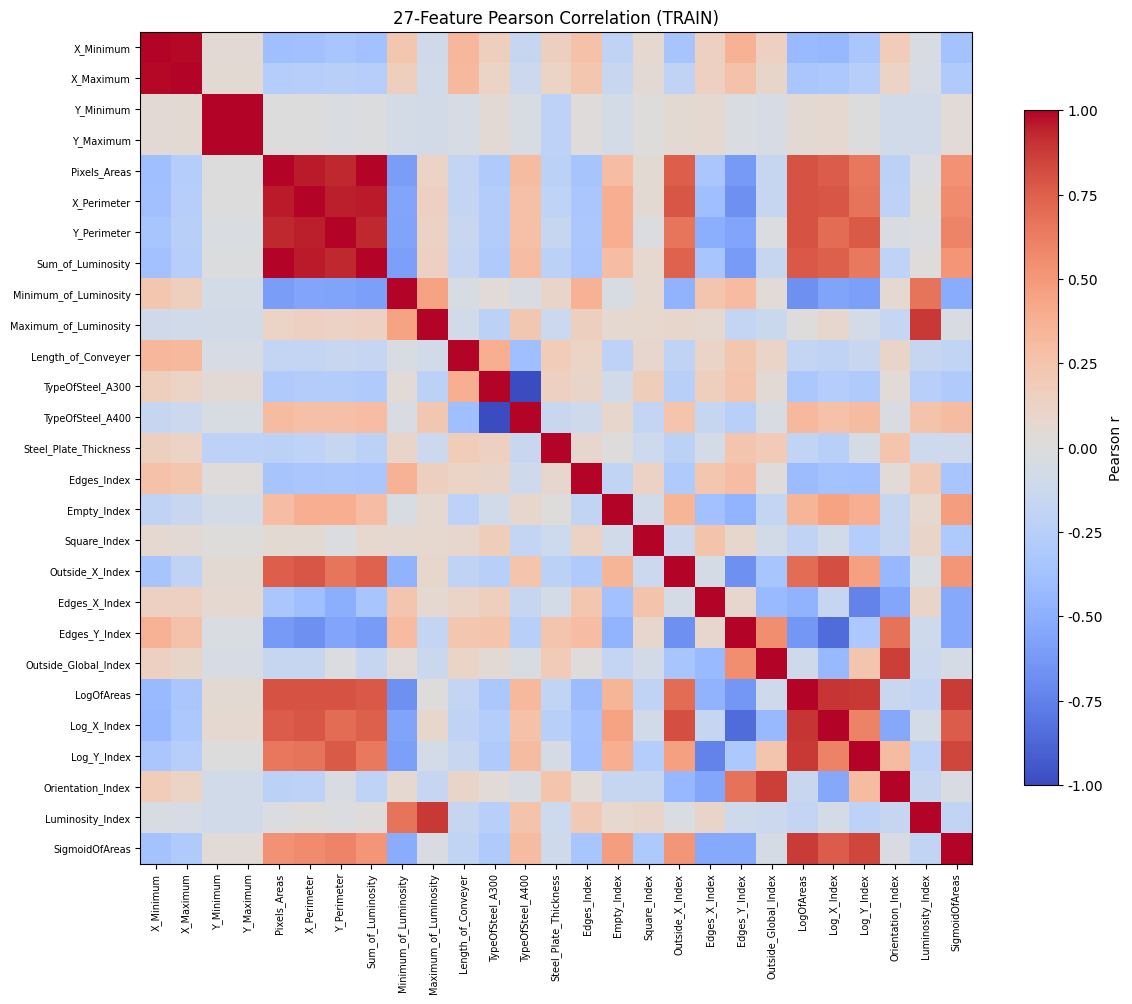

In [8]:
corr = eda[FEATURE_COLS].corr(method="pearson")
save_table(corr.round(6), "11_correlation_matrix.csv")
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
strong_corr = upper.stack().reset_index()
strong_corr.columns = ["변수1", "변수2", "상관계수_r"]
strong_corr = strong_corr.loc[strong_corr["상관계수_r"].abs()>=0.80].copy()
strong_corr = strong_corr.sort_values("상관계수_r", key=lambda s: s.abs(), ascending=False)
display(strong_corr.round(4))
print("|r| >= 0.80인 변수쌍 수:", len(strong_corr))
save_table(strong_corr.round(6), "12_high_correlation_pairs.csv", index=False)

fig, ax = plt.subplots(figsize=(12, 10))
im = ax.imshow(corr.values, vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(np.arange(len(FEATURE_COLS)), labels=FEATURE_COLS, rotation=90, fontsize=7)
ax.set_yticks(np.arange(len(FEATURE_COLS)), labels=FEATURE_COLS, fontsize=7)
fig.colorbar(im, ax=ax, shrink=.8, label="Pearson r")
ax.set_title("27-Feature Pearson Correlation (TRAIN)")
save_figure("11_feature_correlation_heatmap.png")

**[실측 결과]** 절댓값 기준 **0.80 이상**인 입력 변수 쌍이 **19개**였다. 대표적으로 `TypeOfSteel_A300`/`TypeOfSteel_A400` **r=-1.0000**, `Y_Minimum`/`Y_Maximum` **r≈1.0000**, `Pixels_Areas`/`Sum_of_Luminosity` **r=0.9964**, `X_Minimum`/`X_Maximum` **r=0.9870**, `X_Perimeter`/`Sum_of_Luminosity` **r=0.9578**, `Pixels_Areas`/`X_Perimeter` **r=0.9558**이다.

**[그래프 해석]** 강종 표시 변수 두 개는 상호 보완적으로 0/1을 표현하므로 완전한 음의 상관관계가 나타난다. Y 좌표 두 변수는 **상관계수를 소수점 넷째 자리까지 반올림했을 때** 1.0000으로 표시되는 것으로, 두 열이 완전히 동일하다는 뜻은 아니다. 밝기 합계와 면적의 높은 상관성은 두 값이 크기 관련 정보를 상당 부분 공유할 가능성을 보여준다. 따라서 로지스틱 회귀의 계수 해석과 특성 중요도를 검토하되 상관관계만으로 열을 제거하지 않는다.

### 4-9. IQR 기반 이상값 후보 탐색

**분석 목적:** 1사분위수 Q1, 3사분위수 Q3, `IQR=Q3-Q1`을 이용해 `[Q1-1.5×IQR, Q3+1.5×IQR]` 밖의 관측치를 찾아본다. **이상값 후보 ≠ 측정 오류**이며 이 단계에서 어떤 행도 삭제하지 않는다.

,변수,후보 수,후보 비율(%)
0,Sum_of_Luminosity,281,20.69
1,Pixels_Areas,279,20.54
2,X_Perimeter,227,16.72
3,Steel_Plate_Thickness,162,11.93
4,Y_Perimeter,126,9.28
5,Maximum_of_Luminosity,108,7.95
6,Minimum_of_Luminosity,13,0.96
7,Orientation_Index,0,0.00
8,Square_Index,0,0.00
9,Edges_Index,0,0.00


,전체 IQR 기준 면적 이상값 후보 수
Fault,
Pastry,9
Z_Scratch,9
K_Scatch,231
Stains,0
Dirtiness,0
Bumps,5
Other_Faults,25


Pixels_Areas: Q1=84.00, Q3=872.75, 상한=2055.88, 후보=279건


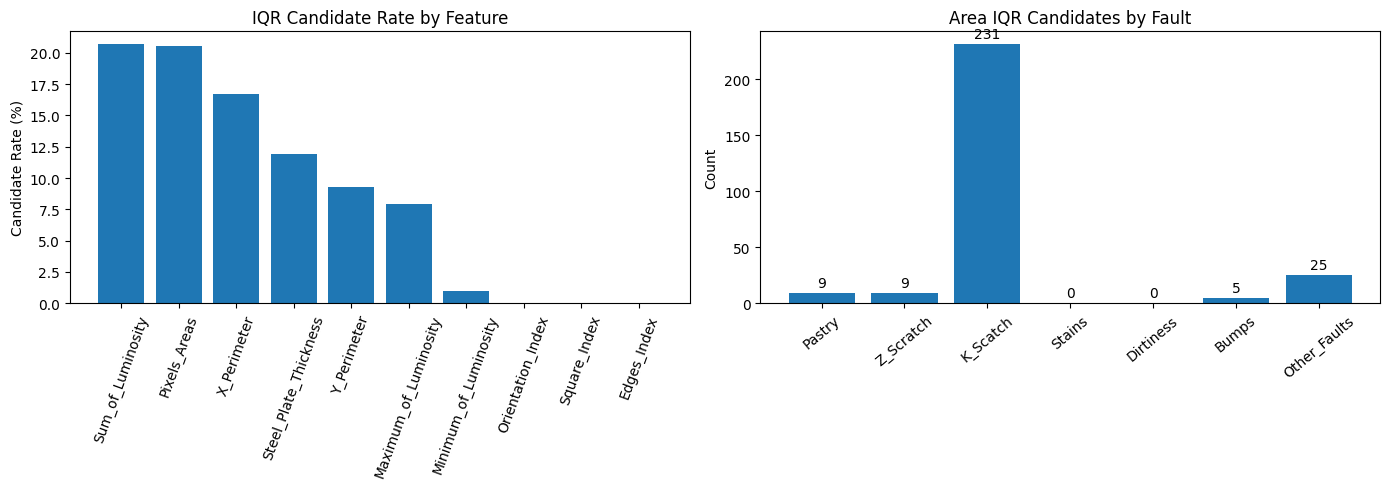

In [9]:
outlier_features = ["Sum_of_Luminosity", "Pixels_Areas", "X_Perimeter", "Steel_Plate_Thickness",
                    "Y_Perimeter", "Maximum_of_Luminosity", "Minimum_of_Luminosity",
                    "Orientation_Index", "Square_Index", "Edges_Index"]
records = []
for feat in outlier_features:
    q1, q3 = eda[feat].quantile([.25, .75]); iqr = q3-q1
    mask = (eda[feat] < q1-1.5*iqr) | (eda[feat] > q3+1.5*iqr)
    records.append({"변수": feat, "후보 수": int(mask.sum()), "후보 비율(%)": round(mask.mean()*100, 2)})
outlier_table = pd.DataFrame(records)
display(outlier_table)
save_table(outlier_table, "13_IQR_outlier_summary.csv", index=False)

q1, q3 = eda["Pixels_Areas"].quantile([.25, .75]); iqr = q3-q1
mask = (eda["Pixels_Areas"] < q1-1.5*iqr) | (eda["Pixels_Areas"] > q3+1.5*iqr)
area_outlier_by_fault = eda.loc[mask, "Fault"].value_counts().reindex(FAULT_COLS, fill_value=0)
display(area_outlier_by_fault.to_frame("전체 IQR 기준 면적 이상값 후보 수"))
save_table(area_outlier_by_fault.to_frame("Count"), "14_area_outliers_by_fault.csv")
print(f"Pixels_Areas: Q1={q1:.2f}, Q3={q3:.2f}, 상한={q3+1.5*iqr:.2f}, 후보={mask.sum()}건")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
bars = axes[0].bar(outlier_table["변수"], outlier_table["후보 비율(%)"])
axes[0].set(title="IQR Candidate Rate by Feature", ylabel="Candidate Rate (%)")
axes[0].tick_params(axis="x", rotation=70)
bars2 = axes[1].bar(area_outlier_by_fault.index, area_outlier_by_fault.values)
axes[1].bar_label(bars2, padding=2)
axes[1].set(title="Area IQR Candidates by Fault", ylabel="Count")
axes[1].tick_params(axis="x", rotation=40)
save_figure("12_outlier_candidates.png")

**[실측 결과]** IQR 기준 이상값 후보는 `Sum_of_Luminosity` **281건(20.69%)**, `Pixels_Areas` **279건(20.54%)**, `X_Perimeter` **227건(16.72%)**, `Steel_Plate_Thickness` **162건(11.93%)**, `Y_Perimeter` **126건(9.28%)**, `Maximum_of_Luminosity` **108건(7.95%)**, `Minimum_of_Luminosity` **13건(0.96%)**이었다. `Orientation_Index`, `Square_Index`, `Edges_Index`는 이 기준에서 **0건**이다.

**[그래프 해석]** `Pixels_Areas` 기준의 후보 279건 가운데 **231건이 `K_Scatch`**이다. 이 유형은 원래 면적 중앙값이 매우 크기 때문에 전체 데이터의 단일 IQR 규칙을 적용하면 결함 유형의 유용한 신호를 오류로 오인할 수 있다. 따라서 후보를 무조건 삭제하지 않고 물리적 타당성·클래스별 분포를 검토한 뒤, 처리 전후 Validation 성능을 비교해야 한다.

### 4-10. 결함 유형별 다변량 특성 종합 비교

**분석 목적:** 단일 변수의 차이를 넘어서 여러 특성의 **유형별 중앙값**이 전체 Train 분포에 비해 상대적으로 높은지/낮은지 비교한다. 이 시각화는 개별 관측치 분류의 증명이 아니다.

,Pixels_Areas,X_Perimeter,Y_Perimeter,Minimum_of_Luminosity,Maximum_of_Luminosity,Luminosity_Index,Orientation_Index,Edges_Index,Square_Index,Steel_Plate_Thickness
Fault,,,,,,,,,,
Pastry,212.5,20.0,31.0,80.0,126.0,-0.18,0.67,0.15,0.33,70.0
Z_Scratch,170.0,30.0,25.0,93.0,124.0,-0.17,0.36,0.14,0.57,70.0
K_Scatch,6282.0,269.0,138.0,40.0,132.0,-0.16,-0.57,0.06,0.43,40.0
Stains,17.0,7.0,5.0,115.5,141.0,-0.00,-0.29,0.47,0.69,50.0
Dirtiness,144.0,28.0,35.0,107.0,133.0,-0.09,0.82,0.90,0.18,100.0
Bumps,122.0,17.0,16.0,91.0,127.0,-0.14,0.10,0.45,0.75,70.0
Other_Faults,147.0,25.0,22.0,97.0,127.0,-0.12,0.18,0.32,0.55,70.0


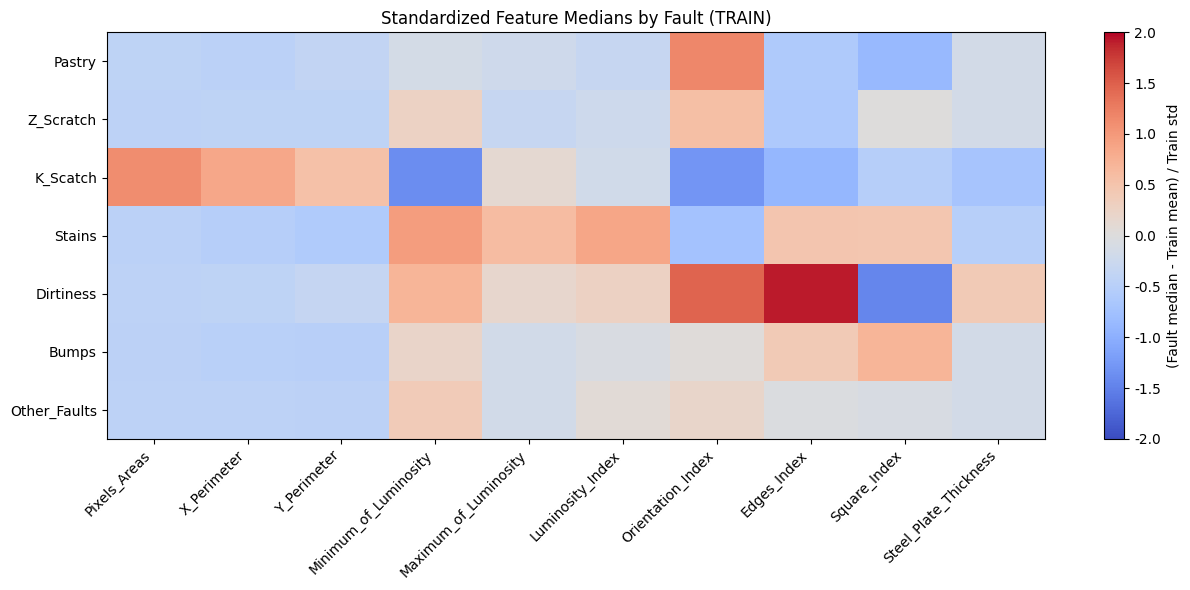

In [10]:
selected = ["Pixels_Areas", "X_Perimeter", "Y_Perimeter", "Minimum_of_Luminosity",
            "Maximum_of_Luminosity", "Luminosity_Index", "Orientation_Index",
            "Edges_Index", "Square_Index", "Steel_Plate_Thickness"]
medians = eda.groupby("Fault")[selected].median().reindex(FAULT_COLS)
means = eda[selected].mean(); stds = eda[selected].std()
nonconstant = stds[stds>0].index
zmed = (medians[nonconstant]-means[nonconstant])/stds[nonconstant]
display(medians.round(2))
save_table(medians.round(4), "15_selected_feature_medians.csv")
save_table(zmed.round(4), "16_standardized_median_profiles.csv")

fig, ax = plt.subplots(figsize=(13, 6))
heat = ax.imshow(zmed, aspect="auto", cmap="coolwarm", vmin=-2, vmax=2)
ax.set_xticks(np.arange(len(zmed.columns)), labels=zmed.columns, rotation=45, ha="right")
ax.set_yticks(np.arange(len(FAULT_COLS)), labels=FAULT_COLS)
fig.colorbar(heat, ax=ax, label="(Fault median - Train mean) / Train std")
ax.set_title("Standardized Feature Medians by Fault (TRAIN)")
save_figure("13_fault_profiles_heatmap.png")

**[그래프 해석]** 히트맵의 각 칸은 해당 결함 유형의 대표값이 전체 Train 평균에 비해 얼마나 높은지 또는 낮은지를 보여준다. `K_Scatch`는 면적과 경계 관련 중앙값이 두드러지고, `Dirtiness`는 일부 형상·방향성 지표에서 다른 유형과 차이를 보인다. 그러나 개별 데이터의 분포가 겹칠 수 있으며, 변수 간 상관관계도 존재한다. 따라서 이러한 패턴이 실제 예측에 어느 정도 기여하는지는 **변수 중요도·Permutation Importance·혼동행렬**로 검증해야 한다.

### 4-11. 종합 분석 결론 및 STEP 4~9 연결

#### (1) 핵심 발견

| 분석 항목 | 확인된 실측 결과 | 분석상 의미 |
|---|---|---|
| 데이터 품질 | 1,941건·34열, 결측 0칸·완전 중복 0건·정답 오류 0건 | 해당 항목의 인위적 보정은 불필요하나 다른 오류는 별도 점검 |
| 클래스 불균형 | Other_Faults 673건(34.67%) / Dirtiness 55건(2.83%), **12.24배** | Macro F1·유형별 Recall 중심의 평가 필요 |
| 면적 분포 | Train 중앙값 K_Scatch 6,282 / Stains 17, 전체 Train 178 | 크기 관련 특징이 유형 구분에 기여할 가능성 |
| 변수 중복성 | |r| ≥ 0.80인 19쌍, 면적–밝기 합계 r=0.9964 | 상관 변수에 대한 해석 주의, 일괄 삭제 금지 |
| 면적 이상값 후보 | Train 279건(20.54%), 이 중 K_Scatch 231건 | 통계적 극단값이 고유 결함 특징일 수 있음 |
| 형상·밝기 차이 | Orientation_Index, 최소 밝기 등에서 유형별 중앙값 차이 | 다변량 모델 검증 대상으로 활용 |

#### (2) 단계별 후속 조치

1. **STEP 4 데이터 전처리:** 결측·중복은 이미 0건으로 검증되었으므로 불필요한 삭제를 피한다. 스케일러·변환 규칙은 Train에서만 학습한다. Test 데이터는 분석 기준 선택에 사용하지 않는다.
2. **STEP 5 Baseline:** Dummy, 로지스틱 회귀, 랜덤 포레스트, 히스토그램 기반 부스팅 등을 동일 조건에서 비교한다.
3. **STEP 6 클래스 불균형 처리:** Class Weight, 오버·언더샘플링, SMOTE 등을 Train에만 적용하고 Macro F1과 소수 클래스 Recall이 개선되는지 검증한다.
4. **STEP 7~9 검증·해석:** 교차검증, 혼동행렬, Permutation Importance로 EDA에서 발견한 크기·명암·형상 패턴이 실제 예측에 활용되는지 평가한다.

#### (3) 보고서용 최종 결론

> 본 프로젝트에서는 Steel Plates Faults 원본 1,941건의 구조와 품질을 확인하고, 학습 데이터 1,358건을 대상으로 주요 입력 특성에 대한 탐색적 데이터 분석을 수행하였다. 그 결과 결함 유형별 표본 수에 12.24배의 차이가 존재했으며, 특히 Other_Faults의 비율이 34.67%로 가장 높았다. 따라서 향후 모델 평가는 전체 정확도뿐 아니라 Macro F1과 클래스별 Recall을 함께 고려할 필요가 있다. 또한 Pixels_Areas 중앙값은 K_Scatch 6,282픽셀, Stains 17픽셀로 차이가 관찰되어 결함 크기가 유형 구분에 도움이 될 가능성이 확인되었다. 한편, 면적과 밝기 합계의 상관계수는 약 0.9964로 나타나 변수 간 정보 중복에 유의할 필요가 있으며, 면적 IQR 이상값 후보 279건 중 231건이 K_Scatch에 집중되어 있었다. 따라서 이상값의 일괄 제거는 지양하고, 후속 단계에서 전처리·불균형 처리의 유효성을 독립 검증 데이터의 실제 성능으로 평가한다.

**한계:** 원본 데이터에 생산 시점·배치 정보가 명확히 주어지지 않았으므로 인과관계나 공정 원인을 추론할 수 없다. 클래스별 중앙값·상관계수·이상값 후보 수는 기술통계 결과이며 실제 분류 정확도나 일반화 성능을 나타내지 않는다.

In [11]:
# 최종 재현성 확인 및 결과 파일 정리
assert len(df)==1941 and len(eda)==1358
assert int(counts.sum())==1941
assert int(counts.loc["Other_Faults"])==673 and int(counts.loc["Dirtiness"])==55
assert len(strong_corr)==19
assert int(outlier_table.loc[outlier_table["변수"]=="Pixels_Areas", "후보 수"].iloc[0])==279
assert int(area_outlier_by_fault.loc["K_Scatch"])==231
print("STEP 3 EDA 검증 완료")
print("분석 표·그래프 저장 위치:", OUT_DIR)
print("저장된 CSV:", len(list(OUT_DIR.glob("*.csv"))), "개")
print("저장된 PNG:", len(list(OUT_DIR.glob("*.png"))), "개")
print("주의: 원본 데이터와 전처리된 Train/Valid/Test 파일은 변경하지 않았습니다.")

STEP 3 EDA 검증 완료
분석 표·그래프 저장 위치: /mnt/data/results/eda_notebook
저장된 CSV: 16 개
저장된 PNG: 11 개
주의: 원본 데이터와 전처리된 Train/Valid/Test 파일은 변경하지 않았습니다.


---
### 부록: VS Code 사용 안내

- 이 `.ipynb`와 `steel_plates_faults.csv`를 **같은 프로젝트 폴더**에 넣는다. 원본은 `Faults.NNA` + `Faults27x7_var` 형식이어도 된다.
- VS Code에서 `.ipynb`를 열고 우측 상단 **커널 선택**에서 프로젝트 Python 환경(예: `.venv314`)을 지정한다.
- 라이브러리 설치: `python -m pip install pandas numpy matplotlib scikit-learn ipykernel`
- 상단 **모두 실행(Run All)** 또는 셀 왼쪽의 ▶를 순서대로 누른다. 이미 저장된 출력만 살펴보려면 실행하지 않아도 된다.
- 표는 `results/eda_notebook/*.csv`, 그림은 `results/eda_notebook/*.png`에 저장된다.
- 원본 `EDA_실측_종합보고서(1).md`의 숫자에 근거하였으며, 이 노트북의 추가 중앙값·그래프는 동일한 원본 CSV와 동일한 분할 규칙에서 재계산한 것이다.